# **4. Preparación de las variables**

El objetivo de esta etapa es seleccionar y transformar las características musicales del conjunto de datos para construir una representación numérica adecuada para comparar canciones.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

### **4.1 Carga y revisión de los datos**

In [2]:
df = pd.read_csv('../data/spotify-tracks-dataset-clean.csv')

print(f'Dimensiones del conjunto de datos: {df.shape}')

display(df.head())

print('\nTipos de datos:')
display(df.dtypes)

Dimensiones del conjunto de datos: (89578, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.210,0.000000,0.1170,0.120,76.332,4,acoustic
1,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.905,0.000071,0.1320,0.143,181.740,3,acoustic
2,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.469,0.000000,0.0829,0.167,119.949,4,acoustic
3,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.4140,0,-8.700,1,0.0369,0.294,0.000000,0.1510,0.669,130.088,4,acoustic
4,4mzP5mHkRvGxdhdGdAH7EJ,Zack Tabudlo,Episode,Give Me Your Forever,74,244800,False,0.627,0.3630,8,-8.127,1,0.0291,0.279,0.000000,0.0928,0.301,99.905,4,acoustic



Tipos de datos:


track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

### **4.2 Selección de características**

In [3]:
audio_features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

X_audio = df[audio_features].copy()

print(f'Dimensiones de X_audio: {X_audio.shape}')

display(X_audio.head())

display(X_audio.describe().T)

Dimensiones de X_audio: (89578, 9)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.438,0.3590,-9.734,0.0557,0.210,0.000000,0.1170,0.120,76.332
1,0.266,0.0596,-18.515,0.0363,0.905,0.000071,0.1320,0.143,181.740
2,0.618,0.4430,-9.681,0.0526,0.469,0.000000,0.0829,0.167,119.949
3,0.625,0.4140,-8.700,0.0369,0.294,0.000000,0.1510,0.669,130.088
4,0.627,0.3630,-8.127,0.0291,0.279,0.000000,0.0928,0.301,99.905


,count,mean,std,min,25%,50%,75%,max
danceability,89578.0,0.563160,0.175270,0.05130,0.4500,0.576000,0.69200,0.985
energy,89578.0,0.635371,0.255712,0.00002,0.4590,0.677000,0.85300,1.000
loudness,89578.0,-8.474706,5.178135,-46.59100,-10.3070,-7.177000,-5.10400,4.532
speechiness,89578.0,0.087597,0.113321,0.02210,0.0360,0.049000,0.08600,0.965
acousticness,89578.0,0.327972,0.338104,0.00000,0.0171,0.187000,0.62400,0.996
instrumentalness,89578.0,0.172569,0.323103,0.00000,0.0000,0.000057,0.09390,1.000
liveness,89578.0,0.216561,0.194346,0.00925,0.0982,0.132000,0.27800,1.000
valence,89578.0,0.470306,0.262357,0.00000,0.2500,0.458000,0.68300,0.995
tempo,89578.0,122.272318,29.707241,30.20000,99.5165,122.021000,140.08775,243.372


### **4.3 Análisis de escalas y distribuciones**

In [4]:
skewness = X_audio.skew()

display(skewness.sort_values(ascending = False).to_frame('skewness'))

,skewness
speechiness,4.545587
liveness,2.066520
instrumentalness,1.570488
acousticness,0.656623
tempo,0.290717
valence,0.129218
danceability,-0.367870
energy,-0.556997
loudness,-1.938588


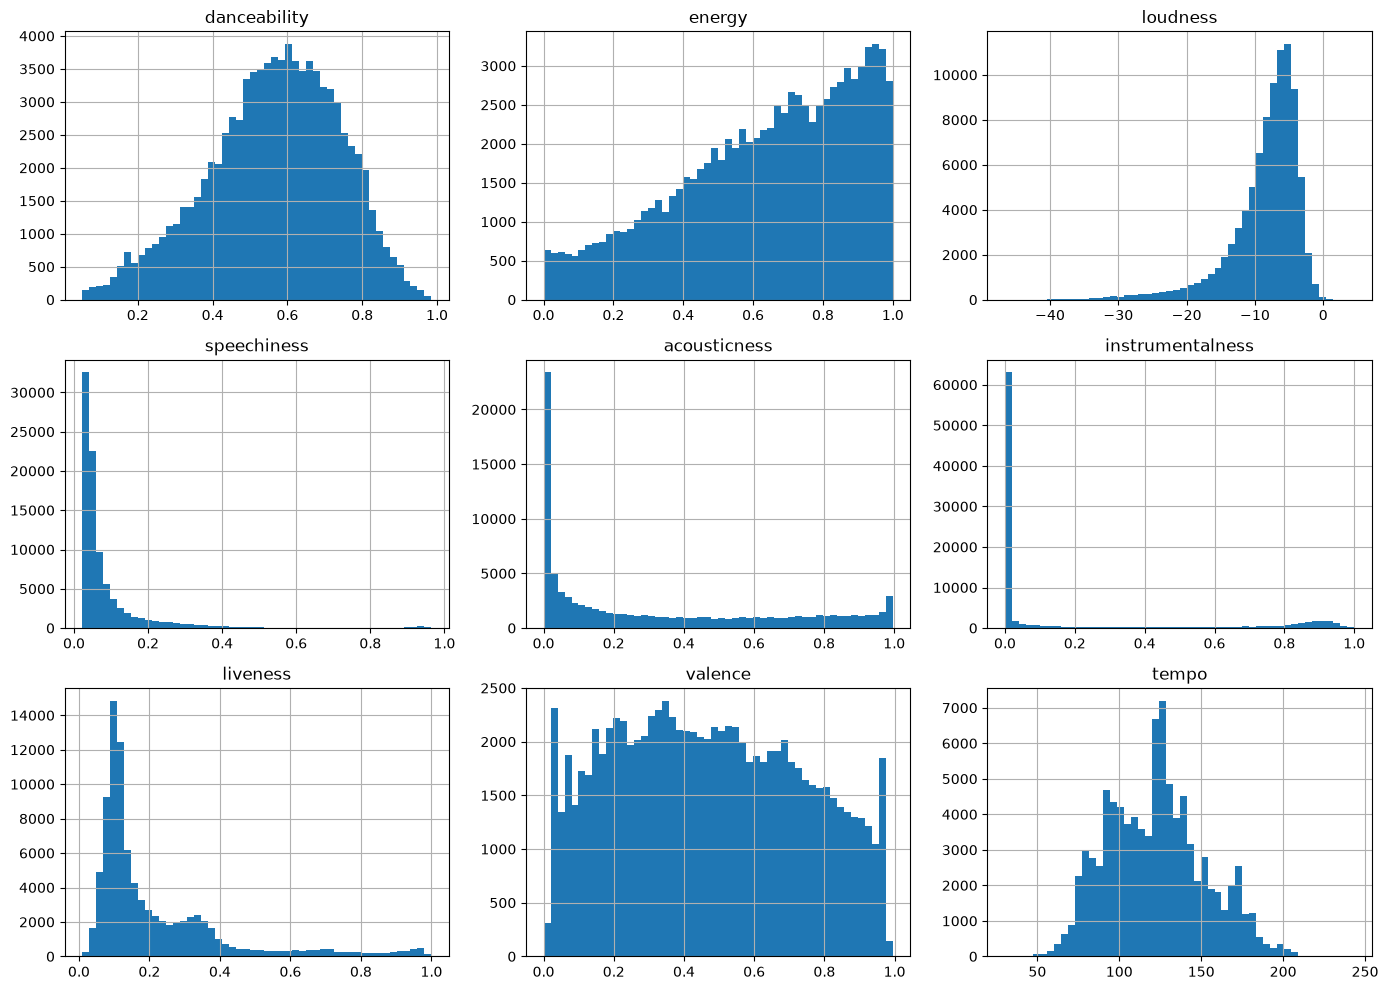

In [5]:
X_audio.hist(bins = 50, figsize = (14, 10), layout = (3, 3))

plt.tight_layout()
plt.show()

### **4.4 Evaluación del escalamiento**

In [6]:
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

X_scaled = {}

for name, scaler in scalers.items():
    X_scaled[name] = pd.DataFrame(
        scaler.fit_transform(X_audio),
        columns = audio_features,
        index = X_audio.index
    )

In [7]:
for name, data in X_scaled.items():
    print(f'\n{name}')
    display(data.describe().T)


StandardScaler


,count,mean,std,min,25%,50%,75%,max
danceability,89578.0,1.015310e-17,1.000006,-2.920433,-0.645639,0.073258,0.735099,2.406819
energy,89578.0,-1.675262e-16,1.000006,-2.484652,-0.689730,0.162797,0.851076,1.425945
loudness,89578.0,8.122483e-17,1.000006,-7.361049,-0.353854,0.250614,0.650953,2.511865
speechiness,89578.0,7.107172e-17,1.000006,-0.577983,-0.455321,-0.340602,-0.014093,7.742700
acousticness,89578.0,1.522966e-17,1.000006,-0.970038,-0.919462,-0.416951,0.875559,1.975819
instrumentalness,89578.0,-4.568897e-17,1.000006,-0.534101,-0.534101,-0.533925,-0.243481,2.560901
liveness,89578.0,-2.792103e-17,1.000006,-1.066720,-0.609028,-0.435110,0.316134,4.031188
valence,89578.0,0.000000e+00,1.000006,-1.792624,-0.839720,-0.046904,0.810709,1.999933
tempo,89578.0,-4.137390e-16,1.000006,-3.099340,-0.766007,-0.008460,0.599703,4.076459



MinMaxScaler


,count,mean,std,min,25%,50%,75%,max
danceability,89578.0,0.548206,0.187715,0.0,0.427011,0.561958,0.686195,1.0
energy,89578.0,0.635364,0.255717,0.0,0.458989,0.676993,0.852997,1.0
loudness,89578.0,0.745580,0.101288,0.0,0.709739,0.770964,0.811513,1.0
speechiness,89578.0,0.069463,0.120183,0.0,0.014742,0.028529,0.067770,1.0
acousticness,89578.0,0.329289,0.339462,0.0,0.017169,0.187751,0.626506,1.0
instrumentalness,89578.0,0.172569,0.323103,0.0,0.000000,0.000057,0.093900,1.0
liveness,89578.0,0.209247,0.196160,0.0,0.089780,0.123896,0.271259,1.0
valence,89578.0,0.472669,0.263676,0.0,0.251256,0.460302,0.686432,1.0
tempo,89578.0,0.431916,0.139358,0.0,0.325167,0.430737,0.515489,1.0



RobustScaler


,count,mean,std,min,25%,50%,75%,max
danceability,89578.0,-0.053057,0.724255,-2.168182,-0.520661,0.0,0.479339,1.690083
energy,89578.0,-0.105657,0.649014,-1.718223,-0.553299,0.0,0.446701,0.819797
loudness,89578.0,-0.249415,0.995221,-7.575245,-0.601576,0.0,0.398424,2.250432
speechiness,89578.0,0.771941,2.266413,-0.538000,-0.260000,0.0,0.740000,18.320000
acousticness,89578.0,0.232282,0.557100,-0.308123,-0.279947,0.0,0.720053,1.333004
instrumentalness,89578.0,1.837188,3.440931,-0.000607,-0.000607,0.0,0.999393,10.649020
liveness,89578.0,0.470307,1.080898,-0.682703,-0.187987,0.0,0.812013,4.827586
valence,89578.0,0.028419,0.605906,-1.057737,-0.480370,0.0,0.519630,1.240185
tempo,89578.0,0.006194,0.732224,-2.263204,-0.554691,0.0,0.445309,2.991059


In [8]:
rng = np.random.default_rng(42)

n_pairs = 10000
n_songs = len(X_audio)

idx_1 = rng.integers(0, n_songs, n_pairs)
idx_2 = rng.integers(0, n_songs, n_pairs)

contributions = {}

for name, data in X_scaled.items():

    differences = (
        data.iloc[idx_1].to_numpy() -
        data.iloc[idx_2].to_numpy()
    )

    contributions[name] = differences**2
    
for name, values in contributions.items():

    contribution_mean = values.mean(axis = 0)

    print(f'{name}')
    display(
        pd.Series(
            contribution_mean,
            index = audio_features
        ).sort_values(ascending = False).to_frame(
            'contribucion_media'
        )
    )

StandardScaler


,contribucion_media
speechiness,2.039279
instrumentalness,2.006946
valence,2.001959
danceability,1.998182
tempo,1.980073
liveness,1.977895
acousticness,1.975534
energy,1.961754
loudness,1.921439


MinMaxScaler


,contribucion_media
acousticness,0.227647
instrumentalness,0.209514
valence,0.139185
energy,0.128280
liveness,0.076106
danceability,0.070409
tempo,0.038454
speechiness,0.029455
loudness,0.019712


RobustScaler


,contribucion_media
instrumentalness,23.761985
speechiness,10.474905
liveness,2.310830
loudness,1.903097
tempo,1.061608
danceability,1.048124
energy,0.826320
valence,0.734956
acousticness,0.613120


In [9]:
quantiles = [0.50, 0.90, 0.95, 0.99, 0.999]

for name, values in contributions.items():

    print(f'{name}')

    result = pd.DataFrame(
        np.quantile(values, quantiles, axis = 0),
        index = quantiles,
        columns = audio_features
    )

    display(result.T)

StandardScaler


,0.500,0.900,0.950,0.990,0.999
danceability,0.929748,5.474840,7.752314,13.002882,18.458168
energy,0.873574,5.597762,7.666241,11.504253,13.712354
loudness,0.472936,4.996979,9.340743,21.544904,38.344802
speechiness,0.070086,3.644014,7.830560,58.040519,65.439715
acousticness,0.768279,6.055517,7.335720,8.443056,8.642945
instrumentalness,0.003880,7.621511,8.208650,8.846417,9.390119
liveness,0.280886,7.049450,11.673255,19.174277,22.185944
valence,1.012572,5.566720,7.448077,10.302713,12.457785
tempo,0.950041,5.398388,7.608771,11.770508,17.465029


MinMaxScaler


,0.500,0.900,0.950,0.990,0.999
danceability,0.032761,0.192915,0.273165,0.458177,0.650402
energy,0.057123,0.366040,0.501298,0.752267,0.896656
loudness,0.004852,0.051265,0.095828,0.221031,0.393383
speechiness,0.001012,0.052633,0.113103,0.838327,0.945199
acousticness,0.088531,0.697795,0.845317,0.972918,0.995952
instrumentalness,0.000405,0.795645,0.856939,0.923518,0.980278
liveness,0.010808,0.271251,0.449167,0.737794,0.853678
valence,0.070398,0.387022,0.517821,0.716287,0.866117
tempo,0.018450,0.104839,0.147766,0.228589,0.339179


RobustScaler


,0.500,0.900,0.950,0.990,0.999
danceability,0.487689,2.871766,4.066389,6.820515,9.682024
energy,0.367962,2.357862,3.229136,4.845764,5.775850
loudness,0.468421,4.949278,9.251575,21.339236,37.978761
speechiness,0.360000,18.717738,40.222233,298.129277,336.135776
acousticness,0.238440,1.879370,2.276690,2.620359,2.682396
instrumentalness,0.045944,90.237710,97.189361,104.740442,111.177803
liveness,0.328167,8.236070,13.638191,22.401847,25.920461
valence,0.371734,2.043645,2.734326,3.782315,4.573482
tempo,0.509361,2.894324,4.079412,6.310710,9.363804


In [10]:
for name, values in contributions.items():
    
    # Distancia total de cada par
    total_distance = values.sum(axis = 1)

    # Identificar pares con distancia distinta de cero
    valid_pairs = total_distance > 0

    # Calcular proporciones únicamente para pares válidos
    proportions = (values[valid_pairs] / total_distance[valid_pairs, None])

    # Contribución porcentual promedio
    mean_proportion = proportions.mean(axis = 0) * 100

    print(f'{name}')
    display(
        pd.Series(
            mean_proportion,
            index = audio_features
        ).sort_values(ascending = False).to_frame(
            'contribucion_media_porcentual'
        )
    )

StandardScaler


,contribucion_media_porcentual
valence,13.767631
tempo,13.630994
danceability,12.623235
acousticness,11.614205
energy,10.986386
liveness,10.823371
instrumentalness,10.462230
loudness,8.681180
speechiness,7.410768


MinMaxScaler


,contribucion_media_porcentual
acousticness,21.834136
valence,17.780017
instrumentalness,16.312371
energy,13.440960
danceability,9.562766
liveness,9.287258
tempo,6.542965
speechiness,3.303993
loudness,1.935534


RobustScaler


,contribucion_media_porcentual
instrumentalness,30.642884
speechiness,17.650559
liveness,11.651352
tempo,8.582951
loudness,8.027114
danceability,7.349887
valence,6.165900
energy,5.362236
acousticness,4.567116


### **4.5 Construcción y validación de la matriz definitiva**

In [11]:
X_audio_scaled = X_scaled['StandardScaler'].copy()

print('Dimensiones:', X_audio_scaled.shape)
print('¿Conserva los índices originales con df?:', X_audio_scaled.index.equals(df.index))
print('¿Conserva los índices originales con X_audio?:', X_audio_scaled.index.equals(X_audio.index))
print('¿Hay valores nulos?:', X_audio_scaled.isna().any().any())
print('¿Todos los valores son finitos?:', np.isfinite(X_audio_scaled.to_numpy()).all())

display(X_audio_scaled.head())

Dimensiones: (89578, 9)
¿Conserva los índices originales con df?: True
¿Conserva los índices originales con X_audio?: True
¿Hay valores nulos?: False
¿Todos los valores son finitos?: True


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,-0.714105,-1.080798,-0.243196,-0.281477,-0.348924,-0.534101,-0.512292,-1.335230,-1.546444
1,-1.695456,-2.251654,-1.938989,-0.452674,1.706669,-0.533882,-0.435110,-1.247563,2.001802
2,0.312890,-0.752301,-0.232960,-0.308834,0.417117,-0.534101,-0.687754,-1.156084,-0.078208
3,0.352829,-0.865711,-0.043509,-0.447379,-0.100478,-0.534101,-0.337345,0.757346,0.263092
4,0.364240,-1.065155,0.067149,-0.516211,-0.144843,-0.534101,-0.636813,-0.645328,-0.752929


### **4.6 Almacenamiento de la matriz definitiva**

In [12]:
X_audio_scaled.to_csv(
    '../data/spotify-audio-features-scaled.csv',
    index = True
)

In [13]:
X_audio_scaled_check = pd.read_csv(
    '../data/spotify-audio-features-scaled.csv',
    index_col = 0
)

print('Dimensiones:', X_audio_scaled_check.shape)
print('¿Coinciden los datos?:', np.allclose(X_audio_scaled.to_numpy(), X_audio_scaled_check.to_numpy()))
print('¿Coinciden los índices?:', X_audio_scaled.index.equals(X_audio_scaled_check.index))

Dimensiones: (89578, 9)
¿Coinciden los datos?: True
¿Coinciden los índices?: True
